# Predicting Bus Arrival Times

## Jasmine Sunga

### November 6, 2026

Jasmine_Sunga_Assignment5_notebook.ipynb

**Research Question:** Which factors determine what time the bus will actually arrive compared to its scheduled time?

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_regression
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Step 1 - Data Ingestion: Transit On Time Performance

In [ ]:
# Load the dataset
train_df = pd.read_csv('complete_on_time_performance_2025_07.csv')

# Inspect the raw dataset
print("Dataset Shape:", train_df.shape)
train_df.head()

Dataset Shape: (1048575, 10)


,Row ID,Stop Number,Route Number,Route Name,Route Destination,Day Type,Scheduled Time,Deviation,Location,Real Time
0,1528579301,62015,641,Lindenwoods West,Beaumont Station,Weekday,2025-07-02T17:37:00,228,POINT (-97.1657705827649 49.848760868678),2025-07-02T17:40:48
1,1528579304,61203,641,Lindenwoods West,Commerce Loop,Weekday,2025-07-02T17:41:07,-52,POINT (-97.1662493980913 49.8486065350738),2025-07-02T17:40:15
2,1528579306,61284,641,Lindenwoods West,Commerce Loop,Weekday,2025-07-02T17:43:55,-14,POINT (-97.1788853714989 49.84699778507),2025-07-02T17:43:41
3,1528579308,60728,641,Lindenwoods West,Commerce Loop,Weekday,2025-07-02T17:44:33,8,POINT (-97.182040519489 49.8470653137884),2025-07-02T17:44:41
4,1528579310,60731,641,Lindenwoods West,Commerce Loop,Weekday,2025-07-02T17:45:42,-43,POINT (-97.1858644935448 49.8452452731907),2025-07-02T17:44:59


## Data Cleaning

### Standardize Column Names

In [11]:
train_df.columns = train_df.columns.str.lower().str.replace(' ', '_')
train_df.head()

,row_id,stop_number,route_number,route_name,route_destination,day_type,scheduled_time,deviation,location,real_time
0,1528579301,62015,641,Lindenwoods West,Beaumont Station,Weekday,2025-07-02T17:37:00,228,POINT (-97.1657705827649 49.848760868678),2025-07-02T17:40:48
1,1528579304,61203,641,Lindenwoods West,Commerce Loop,Weekday,2025-07-02T17:41:07,-52,POINT (-97.1662493980913 49.8486065350738),2025-07-02T17:40:15
2,1528579306,61284,641,Lindenwoods West,Commerce Loop,Weekday,2025-07-02T17:43:55,-14,POINT (-97.1788853714989 49.84699778507),2025-07-02T17:43:41
3,1528579308,60728,641,Lindenwoods West,Commerce Loop,Weekday,2025-07-02T17:44:33,8,POINT (-97.182040519489 49.8470653137884),2025-07-02T17:44:41
4,1528579310,60731,641,Lindenwoods West,Commerce Loop,Weekday,2025-07-02T17:45:42,-43,POINT (-97.1858644935448 49.8452452731907),2025-07-02T17:44:59


### Encode Day Type Columns

In [12]:
train_df['day_type'].unique()

<StringArray>
['Weekday', 'Special', 'Sunday', 'Saturday']
Length: 4, dtype: str

In [13]:
train_df['day_type'] = train_df['day_type'].map({
    'Weekday': 0,
    'Special': 1,
    'Sunday': 2,
    'Saturday': 3
})

train_df.head()

,row_id,stop_number,route_number,route_name,route_destination,day_type,scheduled_time,deviation,location,real_time
0,1528579301,62015,641,Lindenwoods West,Beaumont Station,0,2025-07-02T17:37:00,228,POINT (-97.1657705827649 49.848760868678),2025-07-02T17:40:48
1,1528579304,61203,641,Lindenwoods West,Commerce Loop,0,2025-07-02T17:41:07,-52,POINT (-97.1662493980913 49.8486065350738),2025-07-02T17:40:15
2,1528579306,61284,641,Lindenwoods West,Commerce Loop,0,2025-07-02T17:43:55,-14,POINT (-97.1788853714989 49.84699778507),2025-07-02T17:43:41
3,1528579308,60728,641,Lindenwoods West,Commerce Loop,0,2025-07-02T17:44:33,8,POINT (-97.182040519489 49.8470653137884),2025-07-02T17:44:41
4,1528579310,60731,641,Lindenwoods West,Commerce Loop,0,2025-07-02T17:45:42,-43,POINT (-97.1858644935448 49.8452452731907),2025-07-02T17:44:59


### Date Time Column

Two Options:
- Split both options into seperate columns for year, month, day, hour, minutes, second
- Unix Time Stamp: number of non-leap seconds which have passed since 00:00:00 UTC on Thursday, 1 January 1970


In [14]:
# Convert to datetime
train_df['scheduled_time'] = pd.to_datetime(train_df['scheduled_time'])
train_df['real_time'] = pd.to_datetime(train_df['real_time'])

# Convert to unix timestamps
train_df['scheduled_time'] = train_df['scheduled_time'].apply(
    lambda x: x.timestamp()
)

train_df['real_time'] = train_df['real_time'].apply(
    lambda x: x.timestamp()
)

# Conver to int
train_df['scheduled_time'] = train_df['scheduled_time'].astype('int64')
train_df['real_time'] = train_df['real_time'].astype('int64')

train_df.head()


,row_id,stop_number,route_number,route_name,route_destination,day_type,scheduled_time,deviation,location,real_time
0,1528579301,62015,641,Lindenwoods West,Beaumont Station,0,1751477820,228,POINT (-97.1657705827649 49.848760868678),1751478048
1,1528579304,61203,641,Lindenwoods West,Commerce Loop,0,1751478067,-52,POINT (-97.1662493980913 49.8486065350738),1751478015
2,1528579306,61284,641,Lindenwoods West,Commerce Loop,0,1751478235,-14,POINT (-97.1788853714989 49.84699778507),1751478221
3,1528579308,60728,641,Lindenwoods West,Commerce Loop,0,1751478273,8,POINT (-97.182040519489 49.8470653137884),1751478281
4,1528579310,60731,641,Lindenwoods West,Commerce Loop,0,1751478342,-43,POINT (-97.1858644935448 49.8452452731907),1751478299


## Step 2 - Feature Engineering and Role Assignment

In [15]:
# Define column roles
target_col = "deviation"
meta_cols = ["route_number", "route_destination"]
ignored_cols = ["location", "row_id", "route_name"]

# Use all remaining columns as predictors
feature_cols = [
    c for c in train_df.columns
        if c not in meta_cols + ignored_cols + [target_col]
]

# Ensure the target is numeric and remove rows without a target
train_df[target_col] = pd.to_numeric(train_df[target_col], errors='coerce')
train_df = train_df.dropna(subset=[target_col]).copy()

X_train = train_df[feature_cols]
y_train = train_df[target_col]

print(f"Features ({len(feature_cols)}):", feature_cols)
print("Target Variable:", target_col)
print("Target data type:", y_train.dtype)


Features (4): ['stop_number', 'day_type', 'scheduled_time', 'real_time']
Target Variable: deviation
Target data type: int64


## Step 3 - Inspection: Frame Data

--- Features Data Summary ---
<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 4 columns):
 #   Column          Non-Null Count    Dtype
---  ------          --------------    -----
 0   stop_number     1048575 non-null  int64
 1   day_type        1048575 non-null  int64
 2   scheduled_time  1048575 non-null  int64
 3   real_time       1048575 non-null  int64
dtypes: int64(4)
memory usage: 32.0 MB
None

--- Missing Values in Predictors ---


,Missing Values
stop_number,0
day_type,0
scheduled_time,0
real_time,0



--- Deviation Summary ---
count   1,048,575.00
mean          -94.76
std           474.71
min       -11,518.00
25%          -164.00
50%           -37.00
75%            47.00
max        29,051.00


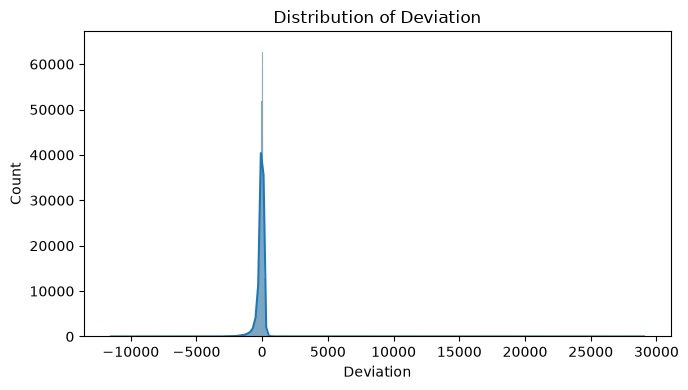

In [16]:
# Display dataset metadata and missing values
print("--- Features Data Summary ---")
print(train_df[feature_cols].info())

print("\n--- Missing Values in Predictors ---")
display(train_df[feature_cols].isna().sum().rename('Missing Values').to_frame())

deviation_summary = train_df['deviation'].describe()
print("\n--- Deviation Summary ---")
print(deviation_summary.to_string(float_format=lambda x: f'{x:,.2f}'))

plt.figure(figsize=(7, 4))
sns.histplot(y_train, kde=True)
plt.title("Distribution of Deviation")
plt.xlabel("Deviation")
plt.tight_layout()
plt.show()

# Exercise 2: Train and Inspect a Decision Tree Regression Model

## Step 4 - Model: Decision Tree Regression Initialization

In Orange, this corresponds to the **Tree** learner configured for a numerical target. Here, use scikit-learn's `DecisionTreeRegressor`, not `DecisionTreeClassifier`. The model predicts a numeric FinalGrade.

In [17]:
# Decision Tree Regressor
dt_model = DecisionTreeRegressor(
    criterion='squared_error',
    min_samples_split=5,
    min_samples_leaf=2,
    max_depth=100,
    random_state=42
)

dt_model.fit(X_train, y_train)
print("Decision Tree Regressor trained.")

Decision Tree Regressor trained.


--- Decision Tree Regression Rules ---
|--- stop_number <= 20098.00
|   |--- stop_number <= 10066.50
|   |   |--- stop_number <= 10009.50
|   |   |   |--- real_time <= 1751460928.00
|   |   |   |   |--- real_time <= 1751442240.00
|   |   |   |   |   |--- scheduled_time <= 1751442112.00
|   |   |   |   |   |   |--- scheduled_time <= 1751434944.00
|   |   |   |   |   |   |   |--- scheduled_time <= 1751397696.00
|   |   |   |   |   |   |   |   |--- scheduled_time <= 1751394112.00
|   |   |   |   |   |   |   |   |   |--- real_time <= 1751380160.00
|   |   |   |   |   |   |   |   |   |   |--- scheduled_time <= 1751375168.00
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |   |   |   |   |   |   |   |--- scheduled_time >  1751375168.00
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |   |   |   |   |   |   |--- real_time >  1751380160.00
|   |   |   |   |   |   |   |   |   |   |--- scheduled_time <= 1751390336.

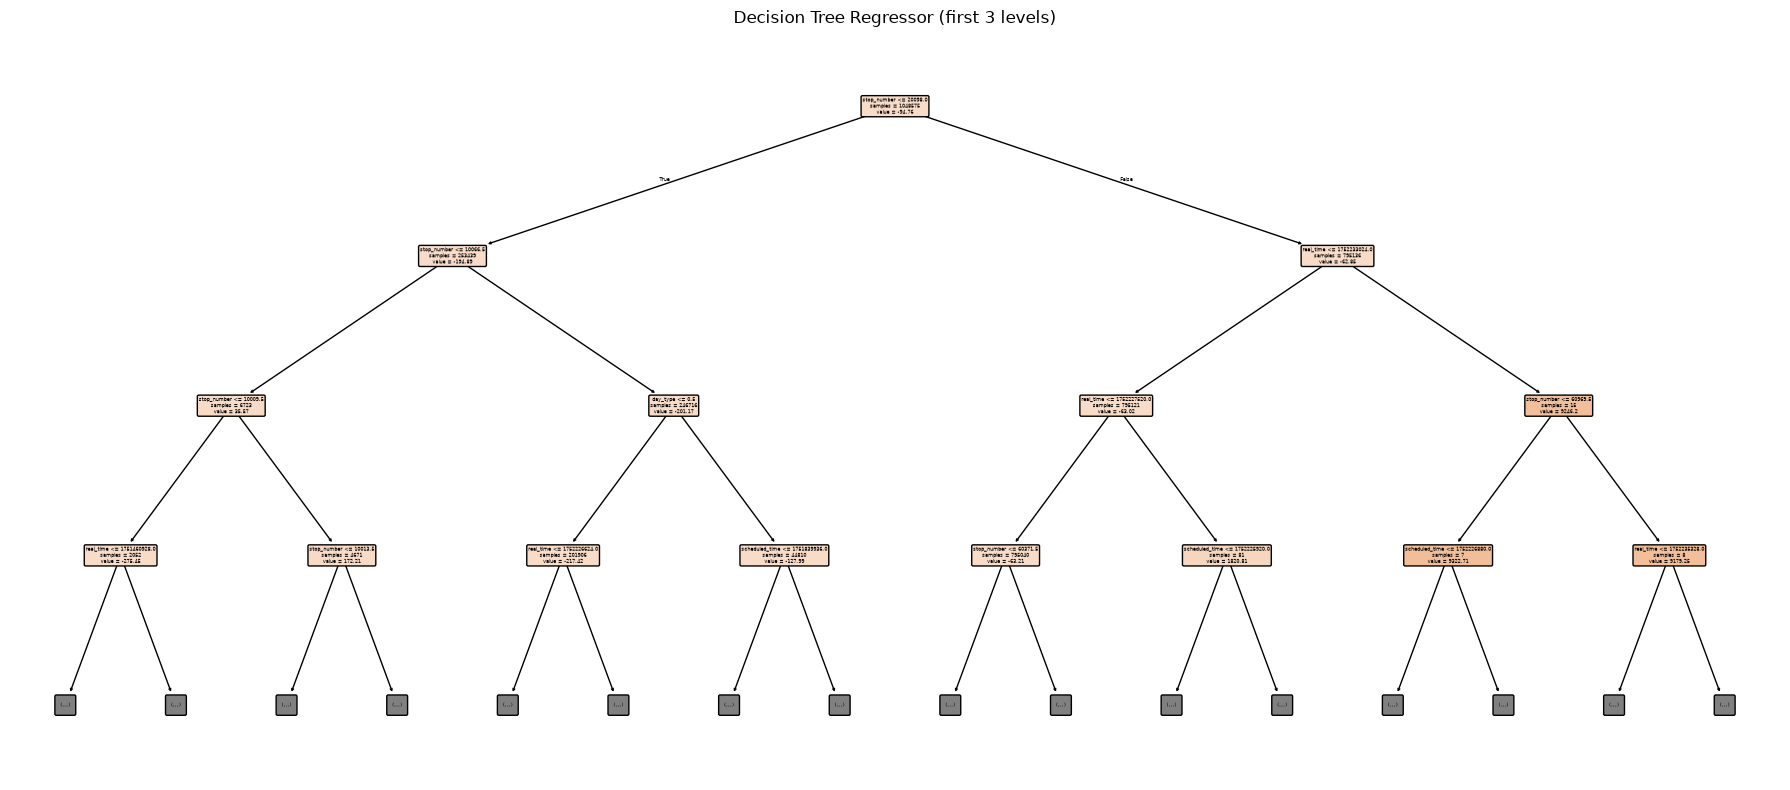

In [18]:
tree_rules = export_text(dt_model, feature_names=list(feature_cols))
print("--- Decision Tree Regression Rules ---")
print(tree_rules)

# Optional visual overview; limit displayed depth to keep the diagram readable
plt.figure(figsize=(18, 8))
plot_tree(
    dt_model,
    feature_names=list(feature_cols),
    filled=True,
    rounded=True,
    max_depth=3,
    impurity=False,
    precision=2
)
plt.title("Decision Tree Regressor (first 3 levels)")
plt.tight_layout()
plt.show()

# Exercise 3: Evaluate Decision Tree and Random Forest Regression Models

## Step 6 - Model: Random Forest Regression Initialization

Configure a **RandomForestRegressor** to predict numerical FinalGrade. A random forest averages predictions from multiple decision trees, which can help produce more stable estimates.

In [19]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    min_samples_split=5,
    random_state=42
)

rf_model.fit(X_train, y_train)
print("Random Forest Regressor trained.")

Random Forest Regressor trained.


## Step 7 - Test and Score (Regression Evaluator)

This is the regression equivalent of Orange's **Test & Score** widget. Use shuffled 5-fold cross-validation to compare both models using:

- **R²**: higher is generally better; 1.0 is a perfect fit, and values below 0 can occur.
- **MAE (Mean Absolute Error)**: average absolute prediction error, in FinalGrade units; lower is better.
- **MSE (Mean Squared Error)** and **RMSE (Root Mean Squared Error)**: penalize larger errors more strongly; lower is better.

The scoring API returns negative values for error metrics so that all scorers follow the convention “higher is better”; the table below converts those scores back to positive error values.

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Decision Tree Regression": dt_model,
    "Random Forest Regression": rf_model
}

scoring = {
    'R2': 'r2',
    'MAE': 'neg_mean_absolute_error',
    'MSE': 'neg_mean_squared_error',
    'RMSE': 'neg_root_mean_squared_error'
}

results = []
for name, model in models.items():
    cv_results = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    results.append({
        'Model': name,
        'R2 (mean)': cv_results['test_R2'].mean(),
        'MAE (mean)': -cv_results['test_MAE'].mean(),
        'MSE (mean)': -cv_results['test_MSE'].mean(),
        'RMSE (mean)': -cv_results['test_RMSE'].mean()
    })

score_board = pd.DataFrame(results).sort_values('R2 (mean)', ascending=False)
display(score_board.round(4))

,Model,R2 (mean),MAE (mean),MSE (mean),RMSE (mean)
0,Decision Tree Regression,0.8391,84.8050,35950.2031,189.2605
1,Random Forest Regression,0.0257,184.0986,219587.2657,468.3648


## Step 8 - Inspection: Regression Error Scoreboard

A confusion matrix is designed for classification and is not appropriate for a continuous numerical target. Instead, inspect cross-validated predictions using actual-versus-predicted plots and residuals (actual minus predicted). Residuals near zero indicate smaller errors; patterns may indicate systematic under- or over-prediction.

--- Decision Tree Regression cross-validation errors ---
R2:   0.8405
MAE:  84.8050
MSE:  35950.2031
RMSE: 189.6054
--- Random Forest Regression cross-validation errors ---
R2:   0.0256
MAE:  184.0986
MSE:  219587.2657
RMSE: 468.6014


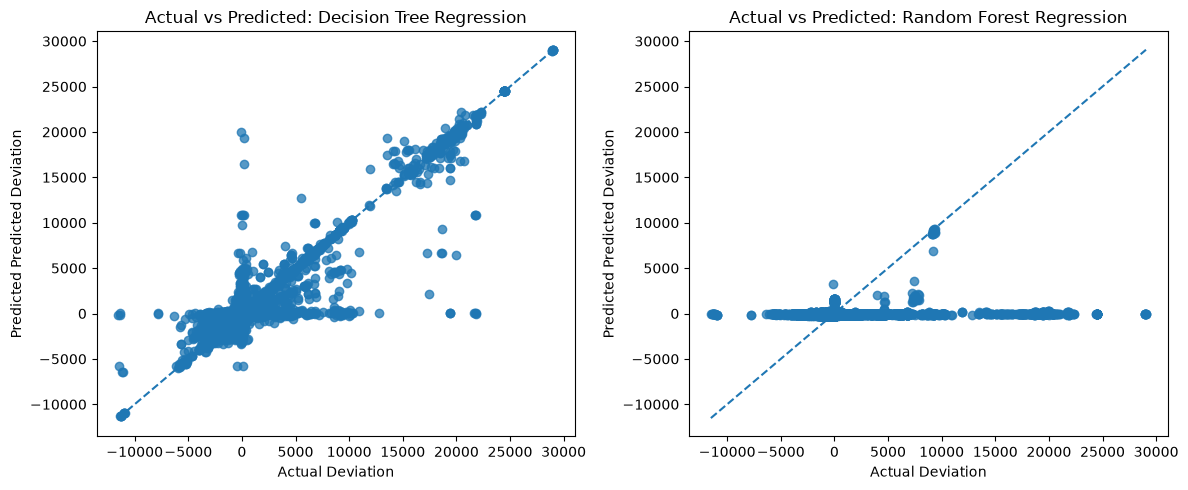

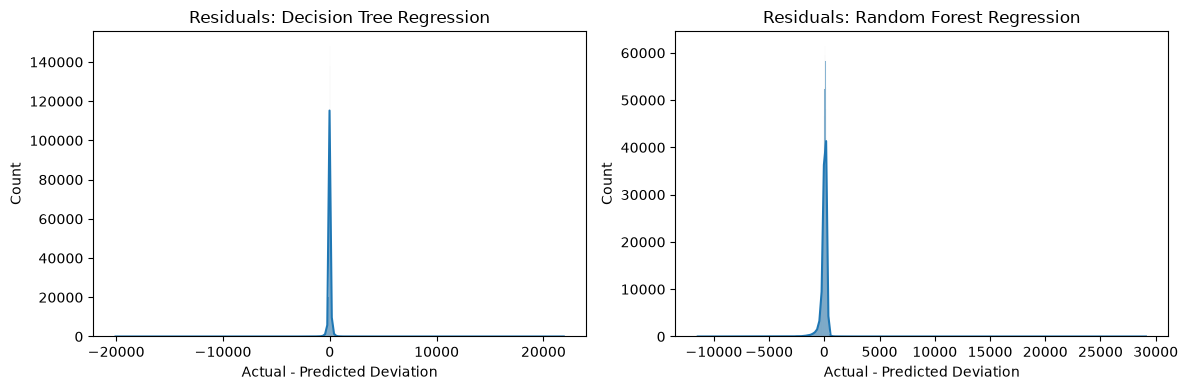

In [22]:
# Generate out-of-fold predictions so each row is predicted by a model
# that did not train on that row's fold.
cv_predictions = {}
for name, model in models.items():
    y_pred_cv = cross_val_predict(model, X_train, y_train, cv=cv)
    cv_predictions[name] = y_pred_cv

    residuals = y_train.to_numpy() - y_pred_cv
    print(f"--- {name} cross-validation errors ---")
    print(f"R2:   {r2_score(y_train, y_pred_cv):.4f}")
    print(f"MAE:  {mean_absolute_error(y_train, y_pred_cv):.4f}")
    print(f"MSE:  {mean_squared_error(y_train, y_pred_cv):.4f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(y_train, y_pred_cv)):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, y_pred_cv) in zip(axes, cv_predictions.items()):
    residuals = y_train.to_numpy() - y_pred_cv
    ax.scatter(y_train, y_pred_cv, alpha=0.75)
    min_val = min(y_train.min(), np.min(y_pred_cv))
    max_val = max(y_train.max(), np.max(y_pred_cv))
    ax.plot([min_val, max_val], [min_val, max_val], linestyle='--')
    ax.set_title(f"Actual vs Predicted: {name}")
    ax.set_xlabel("Actual Deviation")
    ax.set_ylabel("Predicted Predicted Deviation")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, y_pred_cv) in zip(axes, cv_predictions.items()):
    residuals = y_train.to_numpy() - y_pred_cv
    sns.histplot(residuals, kde=True, ax=ax)
    ax.set_title(f"Residuals: {name}")
    ax.set_xlabel("Actual - Predicted Deviation")
plt.tight_layout()
plt.show()

# Exercise 4: Build a Complete Regression Workflow for Business Intelligence

## Step 9 - Data Ingestion: New Incoming Bus Data

Load the incoming bus records for application. This file may include actual `Deviation` values, allowing the workflow to compare model predictions against known outcomes and inspect prediction errors.

In [45]:
unseen_df = pd.read_csv('sample_data/unseen_data.csv')

print("Incoming Dataset Shape:", unseen_df.shape)
display(unseen_df.head())

Incoming Dataset Shape: (100, 10)


,Row ID,Stop Number,Route Number,Route Name,Route Destination,Day Type,Scheduled Time,Deviation,Location,Real Time
0,1553875373,20380,220,Crestview - Westwood,Rouge & Assiniboine,Weekday,2025-07-07T13:40:54,136,POINT (-97.299750983347 49.8755939777549),2025-07-07T13:43:10
1,1553830729,62051,D16,Academy - Notre Dame,RRC Polytech,Weekday,2025-07-06T18:41:21,31,POINT (-97.1752898732082 49.873395633581),2025-07-06T18:41:52
2,1552925450,60408,FX3,Route FX3 Regent - Grant,Redonda & Pandora,Weekday,2025-07-03T17:49:00,44,POINT (-97.2048314110509 49.8570542683905),2025-07-03T17:49:44
3,1554714215,61110,74,Kenaston - Keewatin,University of Manitoba,Weekday,2025-07-09T08:36:34,-147,POINT (-97.2048784930844 49.8174767986043),2025-07-09T08:34:07
4,1555372804,30093,D17,Talbot - Selkirk,Kildonan Place,Sunday,2025-07-13T18:29:00,-286,POINT (-97.1331551061666 49.9117630646681),2025-07-13T18:24:14


### Data Cleaning

In [46]:
# Standardized Column Names
unseen_df.columns = unseen_df.columns.str.lower().str.replace(' ', '_')

# Encode Day Type Column
unseen_df['day_type'] = unseen_df['day_type'].map({
    'Weekday': 0,
    'Special': 1,
    'Sunday': 2,
    'Saturday': 3
})

# Convert datetime 
unseen_df['scheduled_time'] = pd.to_datetime(unseen_df['scheduled_time'])
unseen_df['real_time'] = pd.to_datetime(unseen_df['real_time'])

# Convert to unix timestamps
unseen_df['scheduled_time'] = unseen_df['scheduled_time'].apply(
    lambda x: x.timestamp()
)

unseen_df['real_time'] = unseen_df['real_time'].apply(
    lambda x: x.timestamp()
)

# Conver to int
unseen_df['scheduled_time'] = unseen_df['scheduled_time'].astype('int64')
unseen_df['real_time'] = unseen_df['real_time'].astype('int64')


In [47]:
# Use the same predictors and order as the training data.
missing_features = [c for c in feature_cols if c not in unseen_df.columns]
if missing_features:
    raise ValueError(f"Incoming data is missing required feature(s): {missing_features}")

X_unseen = unseen_df[feature_cols].copy()

# Step 10 - Application: Performance Analysis

## Application: Side by side comparation

Prediction engine that displays the actual outcomes (Pass column) alongside the predicted outcomes from the Random Forest and Decision Tree models, allowing us to compare them side by side and identify correct or incorrect predictions.

In [48]:
predictions_df = unseen_df.copy()

for name, model in models.items():
    predictions_df[f'Predicted_{name}'] = model.predict(X_unseen)

if target_col in predictions_df.columns:
    predictions_df[target_col] = pd.to_numeric(predictions_df[target_col], errors='coerce')
    for name in models:
        pred_col = f'Predicted_{name}'
        predictions_df[f'Residual_{name}'] = predictions_df[target_col] - predictions_df[pred_col]
        predictions_df[f'AbsoluteError_{name}'] = predictions_df[f'Residual_{name}'].abs()

prediction_cols = ([c for c in ['row_id'] if c in predictions_df.columns]
                   + ([target_col] if target_col in predictions_df.columns else [])
                   + [c for c in predictions_df.columns if c.startswith('Predicted_')
                      or c.startswith('Residual_') or c.startswith('AbsoluteError_')])
display(predictions_df[prediction_cols].head(20))

,row_id,deviation,Predicted_Decision Tree Regression,Predicted_Random Forest Regression,Residual_Decision Tree Regression,AbsoluteError_Decision Tree Regression,Residual_Random Forest Regression,AbsoluteError_Random Forest Regression
0,1553875373,136,128.333333,-64.634959,7.666667,7.666667,200.634959,200.634959
1,1553830729,31,35.500000,-57.931720,-4.500000,4.500000,88.931720,88.931720
2,1552925450,44,42.750000,-57.931720,1.250000,1.250000,101.931720,101.931720
3,1554714215,-147,10.000000,-57.931720,-157.000000,157.000000,-89.068280,89.068280
4,1555372804,-286,9359.666667,8582.986072,-9645.666667,9645.666667,-8868.986072,8868.986072
5,1553005519,-1458,-124.333333,-214.377739,-1333.666667,1333.666667,-1243.622261,1243.622261
6,1555117932,-240,9359.666667,8662.034254,-9599.666667,9599.666667,-8902.034254,8902.034254
7,1554377884,-1937,-51.750000,-214.377739,-1885.250000,1885.250000,-1722.622261,1722.622261
8,1554821661,157,182.500000,-64.634959,-25.500000,25.500000,221.634959,221.634959
9,1555220223,-137,1047.500000,1111.118985,-1184.500000,1184.500000,-1248.118985,1248.118985


## Predictive Strength vs. Model Performance

Did the features with the strongest individual correlation/predictive strength end up being the most important predictors in your Decision Tree or Random Forest model?

Mutual_Information (Individual Strength): Measures the direct, single-variable relationship between an input feature and the target variable (e.g., Pass/Fail). A score closer to 0.00 means the feature alone gives almost no information about the target.

RF_Feature_Importance (Model Decision Weight): Measures how much the Random Forest model relied on that feature to split nodes across all its decision trees (Gini Importance). These values sum to 1.00(100%).

In [42]:
# 1. Preliminary Two-way Predictive Strength (Mutual Information for Regression)
mi_scores = mutual_info_regression(X_train, y_train, random_state=42)
mi_df = pd.Series(mi_scores, index=feature_cols, name="Mutual_Information")
 
# 2. Final Model Feature Importance (Random Forest Gini / Impurity Importance)
dt_model = models["Decision Tree Regression"]
dt_importances = pd.Series(
    dt_model.feature_importances_,
    index=feature_cols,
    name="DT_Feature_Importance",
)
 
# 3. Combine both measures into a single comparison DataFrame
comparison_df = pd.concat([mi_df, dt_importances], axis=1).sort_values(
    by="DT_Feature_Importance", ascending=False
)
print("=== Feature Predictive Strength Comparison ===")
print(comparison_df)

=== Feature Predictive Strength Comparison ===
                Mutual_Information  DT_Feature_Importance
scheduled_time            0.077784               0.579957
real_time                 0.077537               0.341965
stop_number               0.140053               0.076278
day_type                  0.001807               0.001800


## Step 11 - Application: Business Intelligence

Create a practical intervention list based on predicted `Deviation`. A bus is marked early if it is more than a minute early and a bus is marked as late if it is more than three minutes late. A bus that meets either requirement is flagged for review to be analyzed for solutions.

In [ ]:
# Set this threshold to match Winnipeg Trannsit Policy
early_threshold = -60
late_threshold = 180

predicted_cols = [f'Predicted_{name}' for name in models]
risk_mask = (predictions_df[predicted_cols] < risk_threshold).any(axis=1)
high_risk_students = predictions_df.loc[risk_mask].copy()

print(f"On Time Threshold: {early_threshold} < Deviation < {late_threshold}")
print(f"Students flagged for review: {len(high_risk_students)} of {len(predictions_df)}")

bi_cols = ([c for c in ['StudentID'] if c in high_risk_students.columns]
           + feature_cols
           + ([target_col] if target_col in high_risk_students.columns else [])
           + predicted_cols)
display(high_risk_students[bi_cols].sort_values(predicted_cols, ascending=True))